In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# 02 · Trends before and after the toll

**Question for this notebook:** what does the raw data show, before any
model? Three comparisons recur in the rest of the project:

* **Toll zone (CBD):** trips that start in one of the 38 CBD taxi zones.
* **Rest of Manhattan:** trips that start in Manhattan above the 60th
  Street border zones and do *not* end in the CBD.
* **Outer boroughs:** the same, for the Bronx, Brooklyn, Queens and
  Staten Island (airports excluded).

Yellow taxis and Uber/Lyft only (green taxis cannot pick up street hails
in the CBD; see notebook 01).

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from congestion.panel import (ANALYSIS_SERVICES, SERVICE_LABEL, complete_dates, load_group_hour,
                              load_zone_day, week_start)
from congestion.plots import COLORS, GROUP_LABEL, mark_policy, save, style, write_metrics

style()
GROUPS = ["cbd", "manhattan_north", "outer"]

In [3]:
zd = load_zone_day()
zd = zd[zd["service"].isin(ANALYSIS_SERVICES) & zd["group"].isin(GROUPS)].copy()
zd["outcome_trips"] = np.where(zd["group"] == "cbd", zd["trips"], zd["trips"] - zd["trips_to_cbd"])
END = complete_dates(zd)
print("Data through", END.date())

Data through 2026-08-31


## 1. Year-on-year growth

Calendar years 2023-2025, plus January-August 2026 against January-August
2024 and 2025.

In [4]:
zd["year"] = zd["date"].dt.year
zd["jan_aug"] = zd["date"].dt.month <= 8


def yearly(df):
    full = df.groupby(["year", "group"])["outcome_trips"].sum().unstack()
    part = df[df["jan_aug"]].groupby(["year", "group"])["outcome_trips"].sum().unstack()
    return full, part


rows = []
for svc in [ANALYSIS_SERVICES, ("hvfhv",), ("yellow",)]:
    full, part = yearly(zd[zd["service"].isin(svc)])
    name = "Taxi + Uber/Lyft" if len(svc) > 1 else SERVICE_LABEL[svc[0]]
    for g in GROUPS:
        rows.append({"service": name, "group": GROUP_LABEL[g],
                     "2023 vs 2022": full.loc[2023, g] / full.loc[2022, g] - 1,
                     "2024 vs 2023": full.loc[2024, g] / full.loc[2023, g] - 1,
                     "2025 vs 2024": full.loc[2025, g] / full.loc[2024, g] - 1,
                     "2026 vs 2025 (Jan-Aug)": part.loc[2026, g] / part.loc[2025, g] - 1})
growth = pd.DataFrame(rows).set_index(["service", "group"])
growth.style.format("{:+.1%}")

Two things stand out before any modelling:

1. Toll-zone trips fell in 2025 while the rest of the city grew. That is
   the headline a quick before/after comparison would report.
2. **The same gap opened in 2024, a year before the toll.** Uber/Lyft
   trips starting in the CBD grew 6-9 points slower than the comparison
   areas from 2023 to 2024, and 5-9 points slower from 2024 to 2025. Any
   estimate that ignores this drift will blame the toll for it.

Yellow taxis behave differently: CBD taxi trips *grew* 9% in 2025, as fast
as taxi trips in the rest of Manhattan. (Yellow trips from the outer
boroughs are a small base that more than doubled in 2024-2025, so taxis
are only compared within Manhattan from here on.)

## 2. The toll zone's share of trips

The ratio of CBD trips to comparison trips, on a log scale and as a
four-week rolling average, set to 0 for the 2024 average. A falling line
means the CBD is losing share. The dashed line extends the 2023-2024 trend.

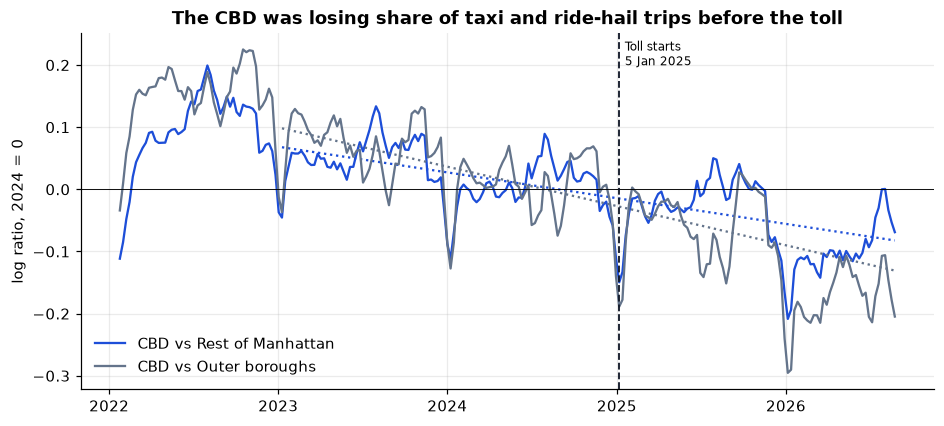

{'Rest of Manhattan': '-4.1% a year', 'Outer boroughs': '-6.1% a year'}


In [5]:
zd["week"] = week_start(zd["date"])
wk = zd[(zd["week"] >= "2022-01-03")].groupby(["week", "group"])["outcome_trips"].sum().unstack()
last_week = week_start(pd.Series([END + pd.Timedelta(days=1)]))[0] - pd.Timedelta(days=7)
wk = wk[wk.index <= last_week]

fig, ax = plt.subplots(figsize=(10, 4.2))
trend_rows = {}
for g in ["manhattan_north", "outer"]:
    r = np.log(wk["cbd"] / wk[g])
    r = r - r["2024-01-01":"2024-12-31"].mean()
    ax.plot(r.index, r.rolling(4).mean(), color=COLORS[g], label=f"CBD vs {GROUP_LABEL[g]}")
    pre = r["2023-01-09":"2024-12-29"]
    t = (pre.index - pre.index[0]).days / 365.25
    slope, icpt = np.polyfit(t, pre.to_numpy(), 1)
    tt = (r["2023-01-09":].index - pre.index[0]).days / 365.25
    ax.plot(r["2023-01-09":].index, icpt + slope * tt, color=COLORS[g], ls=":", lw=1.5)
    trend_rows[g] = float(np.expm1(slope))
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("log ratio, 2024 = 0")
ax.set_title("The CBD was losing share of taxi and ride-hail trips before the toll")
ax.legend(loc="lower left")
mark_policy(ax)
save(fig, "02_cbd_share.png")
plt.show()
print({GROUP_LABEL[k]: f"{v:+.1%} a year" for k, v in trend_rows.items()})

The CBD's share was already falling by about 4-6% a year against both
comparison groups during 2023-2024, and after the toll the lines roughly
continue along their trend until a further step down in January 2026.
(The 2026 step hits Manhattan generally and coincides with strong growth
in southern Brooklyn; notebook 03 treats 2026 as a separate, less certain
second year.)

This picture is the crux of the project: the before/after gap is real, but
most of it is the continuation of a trend that started before the toll.

## 3. Taxis vs Uber/Lyft inside the zone

Taxis pay $0.75 per CBD trip and Uber/Lyft $1.50. Taxis are also mostly
street hails in the core.

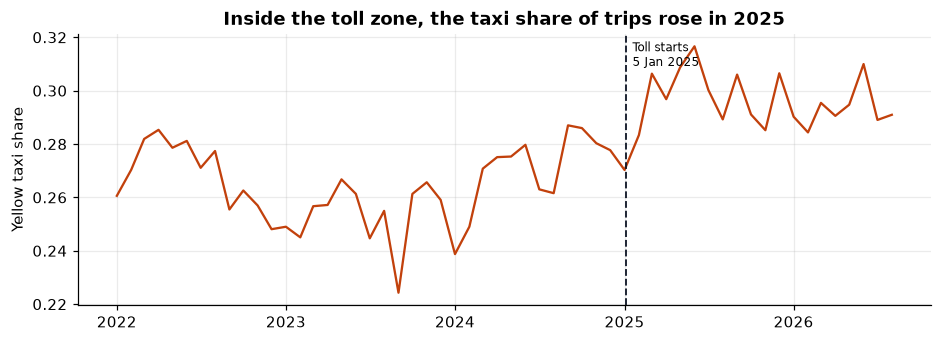

year
2022    26.9%
2023    25.4%
2024    27.1%
2025    29.7%
2026    29.3%
dtype: str

In [6]:
cbd = zd[zd["group"] == "cbd"]
m = cbd.assign(month=cbd["date"].dt.to_period("M").dt.to_timestamp()).groupby(
    ["month", "service"])["trips"].sum().unstack()
m = m[m.index <= END]
share = m["yellow"] / (m["yellow"] + m["hvfhv"])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(share.index, share, color=COLORS["cbd"])
ax.set_ylabel("Yellow taxi share")
ax.set_title("Inside the toll zone, the taxi share of trips rose in 2025")
mark_policy(ax)
save(fig, "02_taxi_share_cbd.png")
plt.show()
yr = cbd.groupby(["year", "service"])["trips"].sum().unstack()
taxi_share = (yr["yellow"] / yr.sum(axis=1))
taxi_share.map("{:.1%}".format)

Taxis went from 27% to 30% of CBD trips. But taxi trips grew just as fast
in the rest of Manhattan, so this may be a Manhattan-wide shift rather than
a response to the cheaper taxi fee; notebook 03 tests it.

## 4. Time of day

Change in CBD-origin trips from 2024 to 2025 by pickup hour. The car toll
is $9 from 5am to 9pm on weekdays and $2.25 overnight; the taxi and
ride-hail fee is the same at all hours.

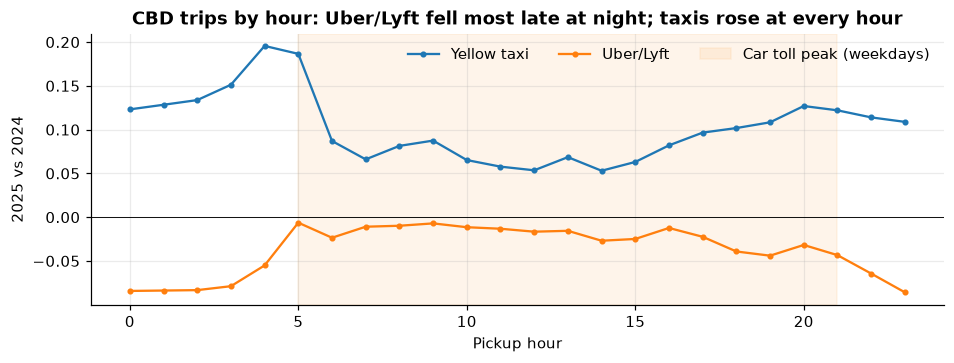

In [7]:
gh = load_group_hour()
gh = gh[gh["service"].isin(ANALYSIS_SERVICES) & (gh["pu_group"] == "cbd")]
gh["year"] = gh["date"].dt.year
hr = gh[gh["year"].isin([2024, 2025])].groupby(["service", "hour", "year"])["trips"].sum().unstack()
hr["change"] = hr[2025] / hr[2024] - 1
fig, ax = plt.subplots(figsize=(10, 3.2))
for svc in ANALYSIS_SERVICES:
    s = hr.loc[svc, "change"]
    ax.plot(s.index, s, marker="o", ms=3, label=SERVICE_LABEL[svc])
ax.axhline(0, color="black", lw=0.6)
ax.axvspan(5, 21, color=COLORS["band"], alpha=0.15, label="Car toll peak (weekdays)")
ax.set_xlabel("Pickup hour")
ax.set_ylabel("2025 vs 2024")
ax.set_title("CBD trips by hour: Uber/Lyft fell most late at night; taxis rose at every hour")
ax.legend(ncol=3)
save(fig, "02_change_by_hour.png")
plt.show()

The Uber/Lyft decline is smallest in the daytime and largest overnight,
when the car toll is lowest and traffic was never the problem. A per-trip
fee that is the same at all hours does not explain that shape well, which
is another hint that the 2025 decline is not mainly about the fee.

In [8]:
cbd_hv = growth.loc[("Uber/Lyft", GROUP_LABEL["cbd"])]
write_metrics("trends", {
    "data_end": END.date().isoformat(),
    "growth": {f"{svc} | {g}": {k: float(v) for k, v in row.items()}
               for (svc, g), row in growth.iterrows()},
    "pre_trend_per_year_vs_manhattan": trend_rows["manhattan_north"],
    "pre_trend_per_year_vs_outer": trend_rows["outer"],
    "taxi_share_cbd": {int(k): float(v) for k, v in taxi_share.items()},
})

Saved reports/metrics/trends.json
